In [1]:
!unzip archive.zip

Archive:  archive.zip
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep3_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep4_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep5_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep6_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep7_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep8_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep9_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep3_label1.npy  
  inflating: pr

In [2]:
path = "/content/processed_repetitions/2d_joints/Ex6"

In [3]:
!pip install optuna
!pip install pywt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]
ERROR: Could not find a version that satisfies the requirement pywt (from versions: none)
ERROR: No matching distribution found for pywt


In [4]:
import os, re, warnings
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from collections import defaultdict
from dataclasses import dataclass

import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, precision_score)
from sklearn.model_selection import train_test_split
from scipy.signal import savgol_filter
import pywt

warnings.filterwarnings("ignore")

In [5]:
SEED      = 42
N_TRIALS  = 40
SAVE_PATH = "/content/kaggle"

def set_seed(s):
    np.random.seed(s)

set_seed(SEED)

In [6]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

### person-disjoint deterministic split (seed 42)

In [8]:
def subject_split(records, test_size=0.2, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based."""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)

    train_persons, test_persons = train_test_split(persons_arr, test_size=test_size, random_state=seed, stratify=strata, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [9]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=7 persons, test=2 persons | train reps P=87, test reps P=17


### joints / bones

In [10]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
JN_R = {v: k for k, v in JN.items()}

BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5),
         (2, 6), (6, 7), (7, 8), (8, 9), (9, 10),
         (2, 11), (11, 12), (12, 13), (13, 14), (14, 15),
         (0, 16), (16, 17), (17, 18), (18, 19), (19, 20),
         (0, 21), (21, 22), (22, 23), (23, 24), (25 * 0 + 24, 25)]

# ghost renderer constants — exact V8 values
K_RES   = 32                 # time-normalized ghost/rep frames
F_POINTS = (0.12, 0.25, 0.4, 0.55, 0.7, 0.85)   # validation-pack progress fractions
ARROW_T = 0.18

### normalization + smoothing + resampling

In [11]:
N_FRAMES = 90
SGF_WIN  = 11
MIN_PHASE = 6

def normalize_clip(arr):
    "(frames,26,2) pixels -> hips-centered / torso-length-scaled per frame (E3)."
    arr = np.asarray(arr, np.float64)
    hips, neck = arr[:, JN["Hips"], :], arr[:, JN["Neck"], :]
    torso = np.linalg.norm(neck - hips, axis=1)
    torso = np.where(torso < 1e-6, 1e-6, torso)
    return (arr - hips[:, None, :]) / torso[:, None, None]

def resample_pose(seq, n=N_FRAMES):
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs, xd = np.arange(T), np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

def smooth_pose(norm, win=SGF_WIN):
    T = norm.shape[0]
    w = min(win if win % 2 == 1 else win + 1, (T // 2) * 2 + 1)
    if w < 5:
        return norm
    return np.stack([savgol_filter(norm[:, j, :], w, 2, axis=0) for j in range(norm.shape[1])], 1)

def resample_flat(mat, n=8):
    """nearest-index resample of a (T,F) matrix to n frames (E3 features_v4.resample_to)."""
    T = mat.shape[0]
    if T == n:
        return mat.copy()
    idx = np.clip(np.round(np.linspace(0, T - 1, n)).astype(int), 0, T - 1)
    return mat[idx]

### angle primitives

In [12]:
def angle_abc(a, b, c):
    """Angle ABC at vertex b (frame arrays ok), degrees — v22 `angle_abc`."""
    ab, bc = np.asarray(a, float) - b, np.asarray(c, float) - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1.0, 1.0)))

def trunk_angle_v(seq):
    """Spine→Neck vs vertical through Spine (v22 verbatim)."""
    g, n = seq[:, JN["Spine"], :], seq[:, JN["Neck"], :]
    ref = np.concatenate([g[:, :1], g[:, 1:2] + 1], axis=1)   # vertical in image coords
    return angle_abc(g, n, ref)

def segment_vertical_angle_series(a, b):
    """Angle of segment a→b from the UPWARD vertical (0,-1) (E3 semantics)."""
    v = b - a
    n = np.linalg.norm(v, axis=-1)
    up = np.array([0.0, -1.0])
    cs = np.clip((v @ up) / np.maximum(n, 1e-9), -1.0, 1.0)
    return np.degrees(np.arccos(cs))

In [13]:
CH_NAMES = ["knee", "hip", "trunk", "lat_pelvic", "foot_sym", "valgus", "kneev", "shin"]
PRIMARY_IDX = 0

def ex6_channels(seq):
    """v22 channels(seq, 6): (T,8) + names."""
    g = lambda n: seq[:, JN[n], :]
    tl = np.linalg.norm(g("Spine") - g("Hips"), axis=-1) + 1e-9
    knee = 0.5 * (angle_abc(g("LeftUpLeg"), g("LeftLeg"), g("LeftFoot")) +
                  angle_abc(g("RightUpLeg"), g("RightLeg"), g("RightFoot")))
    hipf = 0.5 * (angle_abc(g("Hips"), g("LeftUpLeg"), g("LeftLeg")) +
                  angle_abc(g("Hips"), g("RightUpLeg"), g("RightLeg")))
    shin = 0.5 * (angle_abc(g("LeftLeg"), g("LeftFoot"),
                            np.concatenate([g("LeftFoot")[:, :1], g("LeftFoot")[:, 1:2] + 1], axis=1)) +
                  angle_abc(g("RightLeg"), g("RightFoot"),
                            np.concatenate([g("RightFoot")[:, :1], g("RightFoot")[:, 1:2] + 1], axis=1)))
    valg = np.abs(g("LeftLeg")[:, 0] - g("RightLeg")[:, 0]) / tl
    kd = derivative(knee)
    return np.stack([knee, hipf, trunk_angle_v(seq),
                     np.abs(g("Hips")[:, 0] - g("Spine")[:, 0]) / tl,
                     np.abs(g("LeftFoot")[:, 0] - g("RightFoot")[:, 0]) / tl,
                     valg, kd, shin], axis=1)

def derivative(x, h=1.0):
    d = np.zeros_like(x); d[1:-1] = (x[2:] - x[:-2]) / (2 * h); d[0], d[-1] = d[1], d[-2]
    return d

In [14]:
def phase_bounds(p, mode="down"):
    trend = float(p[-1] - p[0])
    s = 1.0 if mode == "up" else -1.0
    t_mid = int(np.argmax(s * (p - p[0]))) if trend * s >= 0 else int(np.argmin(s * (p - p[0])))
    return int(np.clip(t_mid, MIN_PHASE, len(p) - MIN_PHASE))

def phase_stats(x):
    if len(x) < MIN_PHASE:
        return [0.0] * 6
    d = derivative(np.asarray(x, float))
    return [float(np.nanmean(x)), float(np.nanmin(x)), float(np.nanmax(x)),
            float(np.nanmax(x) - np.nanmin(x)), float(np.nanmean(np.abs(d))),
            float(np.nanmax(np.abs(d)))]

def scalar_vector(C):
    """v22 ex_channel_stats for Ex6: (155,) + names (8 channels × 19 + 3 extras)."""
    feats, fnames = [], []
    p_idx = PRIMARY_IDX
    t_mid = phase_bounds(np.nan_to_num(C[:, p_idx]))
    for i, nm in enumerate(CH_NAMES):
        col = np.nan_to_num(C[:, i], nan=0.0)
        whole = phase_stats(col) + [float(np.abs(np.diff(col)).mean())]
        ph0, ph1 = phase_stats(col[:t_mid]), phase_stats(col[t_mid:])
        feats += whole + ph0 + ph1
        fnames += ([f"{nm}_w{m}" for m in range(7)] +
                   [f"{nm}_p0{m}" for m in range(6)] +
                   [f"{nm}_p1{m}" for m in range(6)])
    pcol = np.nan_to_num(C[:, p_idx])
    pol = np.sign(np.mean(np.diff(pcol))) if np.isfinite(np.mean(np.diff(pcol))) else 1.0
    pol = 1.0 if pol == 0 else float(pol)
    ext_t = (np.argmax(pol * pcol) / len(pcol))
    feats += [float(ext_t), float(np.nanstd(pcol)), float(len(pcol)) / N_FRAMES]
    fnames += ["ext_t_norm", "prim_std", "len_norm"]
    return np.nan_to_num(np.array(feats, float)), fnames, t_mid

In [15]:
def dwt_block(C):
    dfeats, dnames = [], []
    for i, nm in enumerate(CH_NAMES):
        coeffs = pywt.wavedec(np.nan_to_num(C[:, i]), "db4", level=3)
        for tag, arr in zip(("cA3", "cD3", "cD2", "cD1"), coeffs):
            dfeats += [float(np.linalg.norm(arr)), float(np.nanmax(np.abs(arr)))]
            dnames += [f"{nm}_{tag}_ln", f"{nm}_{tag}_max"]
    return np.nan_to_num(np.array(dfeats, float)), dnames

def ex6_depth(seq):
    """v22 ex6_depth verbatim: 9 depth/valgus/tempo extras + diagnostics.
    PIXEL-space input required (v22 calls it on v["canon"] = raw pixels
    resampled+smoothed): in hips-centred coords hip_y would be identically 0
    and the depth curve would collapse (the exact ex5 `pelvis_drop` lesson).
    Era verbatim: knee / trunk_shin use the LEFT leg only."""
    g = lambda n: seq[:, JN[n], :]
    tl = np.linalg.norm(g("Spine") - g("Hips"), axis=-1) + 1e-9
    hip_y = g("Hips")[:, 1]
    depth = (hip_y - np.nanpercentile(hip_y, 10)) / tl      # 0 = standing, deep > 0
    # pd.Series(depth).rolling(5, min_periods=1).mean() — exact numpy port
    s = np.nan_to_num(depth)
    isc = np.cumsum(s)
    smooth_d = np.array([
        (isc[min(len(s) - 1, i + 2)] - (isc[i - 3] if i > 2 else 0.0)) /
        (min(len(s) - 1, i + 2) - max(0, i - 2) + 1)
        for i in range(len(s))])
    bottom = int(np.argmax(smooth_d))
    knee = angle_abc(g("LeftUpLeg"), g("LeftLeg"), g("LeftFoot"))       # era: LEFT knee
    lo, hi = max(0, bottom - 3), min(len(depth) - 1, bottom + 3)
    trunk_shin = angle_abc(g("Spine"), g("Hips"), g("LeftLeg"))        # era: trunk vs LEFT thigh
    valg = np.abs(g("LeftLeg")[:, 0] - g("RightLeg")[:, 0]) / tl
    tempo_asym = abs(bottom / max(len(depth), 1) - 0.5)
    feats = np.array([float(np.nanmax(depth)),
                      float(np.nanmean(depth[lo:hi + 1])),
                      float(np.nanmin(knee[lo:hi + 1])),
                      float(trunk_shin[bottom]),
                      float(np.nanmean(valg)), float(np.nanmax(valg)),
                      tempo_asym,
                      float(np.nanmean(derivative(depth))),
                      float(np.nanstd(derivative(depth)))])
    names = ["depth_max", "depth_hold", "knee_at_bottom", "trunk_shin_bottom",
             "valgus_mean", "valgus_max", "tempo_asym", "ddesc", "dasc"]
    return np.nan_to_num(feats), names, bottom, knee

In [16]:
def stats5(x):
    x = np.asarray(x, float)
    return np.array([x.mean(), x.std(), x.min(), x.max(), np.ptp(x)])

def frontness_series(norm):
    return np.abs(norm[:, JN["LeftShoulder"], 0] - norm[:, JN["RightShoulder"], 0])

def e3_ex06_series(norm):
    series = {}
    lk = angle_abc(norm[:, JN["LeftUpLeg"]], norm[:, JN["LeftLeg"]], norm[:, JN["LeftFoot"]])
    rk = angle_abc(norm[:, JN["RightUpLeg"]], norm[:, JN["RightLeg"]], norm[:, JN["RightFoot"]])
    lh = angle_abc(norm[:, JN["Hips"]], norm[:, JN["LeftUpLeg"]], norm[:, JN["LeftLeg"]])
    rh = angle_abc(norm[:, JN["Hips"]], norm[:, JN["RightUpLeg"]], norm[:, JN["RightLeg"]])
    series["knee_flexion"] = 0.5 * (lk + rk)
    series["hip_flexion"] = 0.5 * (lh + rh)
    series["trunk_angle"] = segment_vertical_angle_series(
        norm[:, JN["Spine"]], norm[:, JN["Neck"]])
    mid_sh = 0.5 * (norm[:, JN["LeftShoulder"], :] + norm[:, JN["RightShoulder"], :])
    series["lateral_pelvic_movement"] = np.abs(norm[:, JN["Hips"], 0] - mid_sh[:, 0])
    series["foot_symmetry"] = np.abs(norm[:, JN["LeftFoot"], 0] - norm[:, JN["RightFoot"], 0])
    series["frontness_span"] = frontness_series(norm)
    return series

def e3_c2_vector(norm):
    """E3 build_vector(rep='summ+flat8') over the sorted ex06+frontness series."""
    series = e3_ex06_series(norm)
    keys = sorted(series)
    mat = np.stack([series[k] for k in keys], axis=1).astype(np.float64)
    blocks = [np.concatenate([stats5(mat[:, c]) for c in range(mat.shape[1])])]
    blocks.append(resample_flat(mat, 8).reshape(-1))
    return np.concatenate(blocks), keys

def e3_phase_probe(norm):
    """Per-channel v4 phase probes (peak mean / start mean / whole std) for the
    range-based violation features of the contrastive spec."""
    series = e3_ex06_series(norm)
    keys = sorted(series)
    mat = np.stack([series[k] for k in keys], axis=1).astype(np.float64)
    peak = mat[40:50].mean(axis=0)
    start = mat[0:10].mean(axis=0)
    stab = mat.std(axis=0)
    return peak, start, stab, keys

### feature cache — built once per rep

In [18]:
E1_T = 60                                     # era Ex6 hybrid target_frames family
EX6_JOINTS = [0, 1, 2] + list(range(16, 26))  # E1 v5 mask: spine/hips + legs/feet
MASK54 = np.array(sorted([d for j in EX6_JOINTS for d in (2 * j, 2 * j + 1)] + [52, 53]))

def e1_normalize(seqT):
    """E1 `normalize_spatial_root_relative`: per-frame pelvis centring + STATIC
    frame-0 torso scale (Neck−Hips on frame 0)."""
    pelvis = seqT[:, JN["Hips"], :]
    ctr = seqT - pelvis[:, None, :]
    torso0 = np.linalg.norm(ctr[0, JN["Neck"], :] - ctr[0, JN["Hips"], :])
    return ctr / max(float(torso0), 1e-6)

def ann_super(row):
    """E1 v5 `extract_super_features` on the E1-normalized 60-frame template: (60,54)."""
    seq60 = resample_pose(row["tpl_raw"], E1_T)
    nrm = e1_normalize(seq60)
    coords = nrm.reshape(nrm.shape[0], -1)                                   # (T,52)
    knee = np.linalg.norm(nrm[:, JN["LeftLeg"], :] - nrm[:, JN["RightLeg"], :], axis=-1)
    depth = np.abs(nrm[:, [JN["LeftFoot"], JN["RightFoot"]], 1]).mean(axis=1)
    return np.concatenate([coords, knee[:, None], depth[:, None]], axis=1)   # (T,54)

def build_rep(arr):
    tpl_raw = smooth_pose(resample_pose(np.asarray(arr, np.float64)))   # pixel (90,26,2)
    tpl = normalize_clip(tpl_raw)                                       # E3-normalized
    C = ex6_channels(tpl)
    x155, xnames, t_mid = scalar_vector(C)
    dwt, dnames = dwt_block(C)
    dep, depnames, bottom, knee_series = ex6_depth(tpl_raw)     # era: PIXEL space
    x_all = np.concatenate([x155, dwt, dep])
    c2e3, c2keys = e3_c2_vector(tpl)
    # v4 phase probes on the SAME series the encoder embeds (v22 channels, 90-frame grid)
    peak = np.nanmean(C[40:50], axis=0)      # peak(40:50)
    start = np.nanmean(C[0:10], axis=0)      # start(0:10)
    stab = np.nanstd(C, axis=0)              # whole-clip stability
    return dict(tpl_raw=tpl_raw, tpl=tpl, C=C, x155=x155, xnames=xnames, dwt=dwt,
                dep=dep, x_all=x_all, c2e3=c2e3, c2keys=c2keys,
                peak=peak, start=start, stab=stab, bottom=bottom,
                kb=float(dep[2]), knee_series=knee_series,
                seq=C.astype(np.float32), fname="")

def enrich(records):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr)
        rec = dict(r)
        rec.update(b)
        out.append(rec)
    return out

feat_train = enrich(train)
feat_test  = enrich(test)
_xdim = feat_train[0]["x_all"].shape[0]
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps | "
      f"x155 dims=155, dwt dims={feat_train[0]['dwt'].shape[0]}, dep dims=9, "
      f"x_total={_xdim}, e3 c2 dims={feat_train[0]['c2e3'].shape[0]}")
print("bottom-position spread:", np.percentile([r["bottom"] for r in feat_train + feat_test], [5, 50, 95]).round(1))


cached features: train=127 reps, test=28 reps | x155 dims=155, dwt dims=64, dep dims=9, x_total=228, e3 c2 dims=78
bottom-position spread: [36. 44. 51.]


### metrics (positive class = label 1 = PERFECT)

In [19]:
@dataclass
class ExConfig:
    fbeta: float = 2.0

def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1); acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    fb = (1 + beta ** 2) * prec * rec / max(beta ** 2 * prec + rec, 1e-6)
    mcc = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) >= 2 else 0.0
    auroc = float(roc_auc_score(y_true, y_proba)) if len(np.unique(y_true)) >= 2 else 0.0
    return {"accuracy": acc, "balanced_acc": (rec + spec) / 2.0,
            "precision": prec, "recall": rec, "sensitivity": rec,
            "specificity": spec, "f1": f1, f"f{int(beta)}": fb,
            "mcc": mcc, "auroc": auroc, "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print("                  Predicted PASS  Predicted FAIL")
    if cm.shape == (2, 2):
        tp, fn = cm[0, 0], cm[0, 1]
        fp, tn = cm[1, 0], cm[1, 1]
        print(f"  True PERFECT:  {tp:4d} ({tp / max(tp + fn, 1) * 100:5.1f}%)    "
              f"{fn:4d} ({fn / max(tp + fn, 1) * 100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp / max(tn + fp, 1) * 100:5.1f}%)    "
              f"{tn:4d} ({tn / max(tn + fp, 1) * 100:5.1f}%)")
    else:
        print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true)) < 2:
        return None
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auroc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, color="steelblue", lw=2.5, label=f"ROC (AUROC={auroc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("FPR (1-Specificity)", fontsize=9)
    ax.set_ylabel("TPR (Sensitivity)", fontsize=9)
    ax.set_title(f"{exercise_id} — ROC Curve", fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.4)
    fpath = os.path.join(save_path, f"{exercise_id}_roc.png")
    plt.savefig(fpath, dpi=100, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

### generic runner: Optuna (TPE, seed) → finalize → OOF-Platt gate → flood-proof OOF-quantile cut

In [20]:
class ArchSpec:
    name = "arch"
    supervised = False
    unsup_threshold = False
    min_precision = 0.45
    def search_space(self, trial): raise NotImplementedError
    def build(self, rows, p, seed): raise NotImplementedError
    def score_rows(self, model, rows): raise NotImplementedError
    def ship_scores(self, model, rows): return None

In [21]:
def _is_sup(spec):
    return bool(getattr(spec, "supervised", False))

# era cut: v22 threshold_mcc — MCC-graded sweep with graded precision-floor penalty
def threshold_mcc_graded(p_flawed, y_flawed, min_prec=0.45):
    """Cut on P(flawed): sweep 91 candidates; score = MCC − 2×(min_prec−precision)
    when below the floor; ties prefer the HIGHER cut. Landed 'floor_ok' bool."""
    cands = []
    for t in np.linspace(0.05, 0.95, 91):
        pred = (p_flawed >= t).astype(int)          # FAIL if p_flawed >= t
        if pred.sum() == 0 or pred.sum() == len(pred):
            continue
        prec = precision_score(y_flawed, pred, zero_division=0)
        mcc = matthews_corrcoef(y_flawed, pred) if len(set(pred)) > 1 else 0.0
        score = mcc - (2.0 * (min_prec - prec) if prec < min_prec else 0.0)
        cands.append((score, float(t), mcc, prec, bool(prec >= min_prec and mcc > 0.15)))
    if not cands:
        return 0.5, False
    best_score = max(c[0] for c in cands)
    pool = [c for c in cands if c[0] >= best_score - 1e-12]
    best = max(pool, key=lambda c: (c[1], c[0]))
    return best[1], bool(best[4])

def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    """Inner person-disjoint split; objective = MCC(cut) + AUROC on inner-val."""
    persons = sorted({r["person_id"] for r in rows}, key=str)
    rng = np.random.RandomState(SEED)
    val_p = set(persons[i] for i in rng.permutation(len(persons))[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train reps={len(tr_r)} val reps={len(va_r)} "
          f"(person-disjoint: {len({r['person_id'] for r in tr_r})}/{len(val_p)} persons)")

    def objective(trial):
        p = spec.search_space(trial)
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s_tr = spec.score_rows(model, tr_r)
        s_va = spec.score_rows(model, va_r)
        y_tr = np.array([r["label"] for r in tr_r])
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p.get("q", 80.0)) if _is_sup(spec) \
            else np.percentile(s_tr, p.get("q", 80.0))
        mcc = matthews_corrcoef(1 - y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(1 - y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner())
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    full_p = spec.search_space(optuna.trial.FixedTrial(study.best_params))
    study.set_user_attr("best_full_params", full_p)
    return study

def finalize_for(spec, study, feat_train, feat_test):
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    Xc_rows = [r for r in feat_train if r["label"] == 1]
    set_seed(SEED)
    fit_rows = feat_train if _is_sup(spec) else Xc_rows
    model = spec.build(fit_rows, p, SEED)
    thr_rows = feat_train if getattr(spec, "unsup_threshold", False) else Xc_rows
    s_thr = spec.score_rows(model, thr_rows)
    thr = float(np.percentile(s_thr, p.get("q", 80.0)))
    print(f"provisional score threshold: {thr:.6f}")

    st = spec.score_rows(model, feat_test)
    yt = np.array([r["label"] for r in feat_test])
    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, -st, spec.name)
    return dict(spec=spec, params=p, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=list(feat_test), study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    """Person-disjoint folds; OOF Platt fitted on RAW scores, target = FLAWED.
    Era degenerate guards (slope <= 1e-6 or calibrated span < 0.15 -> identity)."""
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    persons = sorted({f["person_id"] for f in feat_train}, key=str)
    assert len(persons) >= 2 * n_folds, "too few persons for OOF-Platt folds"
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(persons))
    folds = [set(np.array(persons)[c].tolist()) for c in np.array_split(perm, n_folds)]

    pl, ys, rows_oof = [], [], []
    for ps in folds:
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s = spec.score_rows(model, te_r)
        pl += [s]; ys += [1 - r["label"] for r in te_r]            # flawed = 1
        rows_oof += list(te_r)
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)

    ab = _platt_fit_raw(pl, ys)
    a = ab[0]
    p_flawed = platt_p_flawed(ab, pl)
    if a <= 1e-6 or (np.nanpercentile(p_flawed, 95) - np.nanpercentile(p_flawed, 5)) < 0.15:
        a, ab, p_flawed = 1.0, (1.0, 0.0), pl
    auroc = roc_auc_score(ys, p_flawed) if len(set(ys)) == 2 else float("nan")
    gate = "PASS" if (auroc > 0.5 and a > 0) else "*** FAIL — do not ship verdicts ***"
    print(f"  Platt a={a:.3f} b={ab[1]:.3f} | OOF AUROC(flawed)={auroc:.3f} [{gate}] | "
          f"P(flawed): correct={p_flawed[ys == 0].mean():.3f} flawed={p_flawed[ys == 1].mean():.3f}")
    return {"a": a, "b": ab[1], "oof_auroc": auroc, "oof_p": p_flawed, "oof_y": ys,
            "oof_persons": [str(r["person_id"]) for r in rows_oof]}

def _platt_fit_raw(scores, y_flawed):
    """2-parameter Platt on raw OOF scores (era guards)."""
    scores = np.asarray(scores, float); yv = np.asarray(y_flawed, int)
    if len(set(yv)) < 2 or np.nanstd(scores) < 1e-9:
        return (1.0, 0.0)
    lr = LogisticRegression(C=1e5, max_iter=1000).fit(np.nan_to_num(scores).reshape(-1, 1), yv)
    a, b = float(lr.coef_[0][0]), float(lr.intercept_[0])
    if a <= 1e-6:
        return (1.0, 0.0)
    cal = platt_p_flawed((a, b), scores)
    if (np.nanpercentile(cal, 95) - np.nanpercentile(cal, 5)) < 0.15:
        return (1.0, 0.0)
    return (a, b)

def platt_p_flawed(ab, scores):
    a, b = float(ab[0]), float(ab[1])
    if a == 1.0 and b == 0.0:
        return np.asarray(scores, float)
    z = a * np.nan_to_num(np.asarray(scores, float)) + b
    return 1.0 / (1.0 + np.exp(-z))

In [22]:
TRAIN_CORRECT = [r for r in feat_train if r["label"] == 1]

# population reference (ghost retrieval + personal bank share these):
CORRECT_X = np.stack([r["x155"] for r in TRAIN_CORRECT])
POP_LO, POP_HI = np.percentile(CORRECT_X, 25, 0), np.percentile(CORRECT_X, 75, 0)
POP_MED   = np.median(CORRECT_X, 0)
POP_BAND  = np.maximum(POP_HI - POP_LO, 1e-9)

# per-feature "wrong side" sign (era: corr of feature with correct-label)
_ytr = np.array([1 - r["label"] for r in feat_train], int)      # flawed = 1
_Xtr = np.nan_to_num(np.stack([r["x155"] for r in feat_train]))
corrfeats = []
for j in range(_Xtr.shape[1]):
    col = _Xtr[:, j]
    corrfeats.append(0.0 if col.std() < 1e-9 else float(np.corrcoef(col, 1 - _ytr)[0, 1]))
FEAT_CORR = np.array(corrfeats)

def train_channel_banks():
    """v22 train_side_bank: per named channel, (p5,p95) of pooled correct-train frames."""
    banks = {}
    for i, nm in enumerate(CH_NAMES):
        A = np.concatenate([r["C"][:, i] for r in TRAIN_CORRECT])
        banks[nm] = (float(np.nanpercentile(A, 5)), float(np.nanpercentile(A, 95)))
    return banks

CHAN_BANKS = train_channel_banks()

# era MSGS[6] verbatim (v22)
MSGS = {
    "knee":       "Bend the knees deeper at the bottom.",
    "trunk":      "Keep chest lifted — avoid folding forward.",
    "lat_pelvic": "Knees track over toes — don't sway.",
    "foot_sym":   "Feet evenly spaced — stable base.",
}

def corrections_for(row, top_k=3):
    res = []
    for ch, msg in MSGS.items():
        i0 = CH_NAMES.index(ch)
        col = np.nan_to_num(row["C"][:, i0])
        below = float((col < CHAN_BANKS[ch][0]).mean())
        above = float((col > CHAN_BANKS[ch][1]).mean())
        off = max(below, above)
        if off > 0.15:
            res.append((off, msg, "above" if above > below else "below"))
    res.sort(reverse=True, key=lambda x: x[0])
    return [{"msg": m, "sev": round(o, 3), "dir": d} for o, m, d in res[:top_k]]

# ---- V8 critique (E3-V7 CRIT_KEYS[6] + V8 flagship 'knee at bottom') ----
def _kb(row):
    lo, hi = max(0, row["bottom"] - 3), min(N_FRAMES - 1, row["bottom"] + 3)
    return float(np.nanmin(row["C"][lo:hi + 1, PRIMARY_IDX]))

CRIT = [
    ("knee_bottom",  "knee angle at the bottom", ("bottom", _kb)),
    ("knee",         "knee flexion",             ("chan", 0)),
    ("trunk",        "trunk lean angle",         ("chan", 2)),
    ("lat_pelvic",   "lateral pelvic sway",      ("chan", 3)),
    ("foot_sym",     "foot stance width",        ("chan", 4)),
    ("valgus_mean",  "knee valgus separation",   ("chan", 5)),
]

def _crit_val(row, src):
    kind, fn = src
    if kind == "bottom":
        return float(fn(row))
    return float(row["C"][:, fn].mean())

def rule_quantiles(rows):
    q = {}
    y = np.array([r["label"] for r in rows], float)
    for nm, _disp, src in CRIT:
        vals = np.array([_crit_val(r, src) for r in rows])
        if vals.std() > 1e-9:
            corr = float(np.corrcoef(vals, (y == 1).astype(float))[0, 1])
        else:
            corr = 0.0
        q[nm] = dict(q25=float(np.percentile(vals, 25)), med=float(np.percentile(vals, 50)),
                     q75=float(np.percentile(vals, 75)),
                     iqr_wide=float(np.percentile(vals, 75) - np.percentile(vals, 25)),
                     corr=corr)
    return q

RULE_Q = rule_quantiles(feat_train)

def qtable_for(row):
    return RULE_Q

def critique_deficits(row):
    """V7 critique: wrong-side IQR deficits, clipped [0,6], IQR floored at 25% wide."""
    qt = qtable_for(row)
    out = {}
    for nm, _disp, src in CRIT:
        info = qt[nm]
        v = _crit_val(row, src)
        iqr = max(info["q75"] - info["q25"], 0.25 * info["iqr_wide"]) + 1e-9
        wrong_dir_higher = info["corr"] < 0        # higher value → less correct
        d = (v - info["med"]) / iqr if wrong_dir_higher else (info["med"] - v) / iqr
        out[nm] = float(np.clip(d, 0.0, 6.0)) if d > 0 else 0.0
    return out

def correction_cue(row):
    """V8 cue text: worst rule + values vs reference (era wording)."""
    d = critique_deficits(row)
    if not d or max(d.values()) <= 0:
        return "no rule deficit beyond the correct-reference band"
    nm = max(d, key=lambda k: d[k])
    disp = dict((nm_, d_) for nm_, d_, _ in CRIT)[nm]
    v = _crit_val(row, dict((nm_, s_) for nm_, _d, s_ in CRIT)[nm])
    info = qtable_for(row)[nm]
    cue = (f"{disp}: {v:.2f} (reference correct reps: median {info['med']:.2f}, "
           f"typical {info['q25']:.2f} to {info['q75']:.2f})")
    extra = [f"{dict((nm_, d_) for nm_, d_, _ in CRIT)[k]} sev {v_:.2f}"
             for k, v_ in d.items() if k != nm and v_ >= 0.25]
    return cue + ("; also " + ", ".join(extra) if extra else "")

In [23]:
def draw_skeleton(ax, pose26, color, ls="-", lw=2.0, alpha=1.0, ms=5, z=2):
    for a, b in BONES:
        ax.plot([pose26[a, 0], pose26[b, 0]], [pose26[a, 1], pose26[b, 1]],
                color=color, linestyle=ls, linewidth=lw, alpha=alpha, zorder=z)
    ax.scatter(*pose26.T, s=ms * 4, color=color, alpha=alpha, zorder=z + 1)

def ghost_for(row):
    """V8 retrieval: nearest correct bank rep by IQR-band-normalized 155-dim dist.
    Band floored at 25% of the population band (V7 IQR floor; degenerate dims)."""
    bank = [r for r in TRAIN_CORRECT if str(r["person_id"]) != str(row["person_id"])]
    Zq = row["x155"]
    Zb = np.stack([r["x155"] for r in bank])
    lo, hi = np.percentile(Zb, 25, axis=0), np.percentile(Zb, 75, axis=0)
    band = np.maximum(np.maximum(hi - lo, 0.25 * POP_BAND), 1e-9)
    dz = (Zq[None, :] - Zb) / band[None, :]
    return bank[int(np.argmin(np.linalg.norm(dz, axis=1)))]

def ghost_render(row, ghost_row, fpoints=F_POINTS, arrows=True, title=None,
                 save_name=None, prob=None, truth=None, sync=True):
    """V8 panel: K_RES frames, orange dashed ghost vs blue performer,
    green arrows only for joints displaced > ARROW_T torso units, y-down flip.
    Phase-sync matches each panel to the ghost frame with the same POSE VALUE
    (n primary knee angle), falling back to plain time-normalized panels
    when either curve is flat (hold-depth reps)."""
    cur = row["tpl"]
    gho = ghost_row["tpl"]
    tc = row["C"][:, PRIMARY_IDX].reshape(-1, 1)
    tg = ghost_row["C"][:, PRIMARY_IDX].reshape(-1, 1)
    pc = resample_flat(tc, K_RES).ravel()
    pg = resample_flat(tg, K_RES).ravel()
    sync = sync and min(float(pc.max() - pc.min()), float(pg.max() - pg.min())) > 10.0
    fig, axes = plt.subplots(1, len(fpoints), figsize=(2.3 * len(fpoints), 3.4))
    if title is None:
        title = f"Ghost overlay — {row['person_id']} rep{row['rep']}  " \
                f"truth={'FLAWED' if row['label'] == 0 else 'PERFECT'}"
    for ax, tfrac in zip(np.atleast_1d(axes), fpoints):
        i = min(int(round(tfrac * (K_RES - 1))), K_RES - 1)
        j = int(np.argmin(np.abs(pg - pc[i]))) if sync else i
        src_i = np.clip(np.round(np.linspace(0, N_FRAMES - 1, K_RES)).astype(int), 0, N_FRAMES - 1)
        cj, gj = cur[src_i[i]], gho[src_i[j]]
        disp = np.linalg.norm(cj - gj, axis=1)
        if arrows:
            for jn in np.where(disp > ARROW_T)[0]:
                ax.annotate("", xy=gj[jn], xytext=cj[jn],
                            arrowprops=dict(arrowstyle="->", color="green",
                                            lw=1.3, alpha=0.75, shrinkA=6, shrinkB=6),
                            zorder=1)
        draw_skeleton(ax, gj, "#e8743b", ls="--", lw=1.8, ms=3, z=2, alpha=0.95)
        draw_skeleton(ax, cj, "#2a6fd6", lw=2.4, ms=4, z=3)
        m = 0.55
        lo_x, hi_x = min(cj[:, 0].min(), gj[:, 0].min()) - m, max(cj[:, 0].max(), gj[:, 0].max()) + m
        lo_y, hi_y = min(cj[:, 1].min(), gj[:, 1].min()) - m, max(cj[:, 1].max(), gj[:, 1].max()) + m
        ax.set_xlim(lo_x, hi_x); ax.set_ylim(hi_y, lo_y)      # y-down → flip
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{int(tfrac * 100)}%", fontsize=8)
    sm_ghost = plt.Line2D([0], [0], color="#e8743b", ls="--", lw=2, label="ghost (correct ref)")
    sm_user = plt.Line2D([0], [0], color="#2a6fd6", lw=2, label="performed rep")
    fig.legend(handles=[sm_ghost, sm_user], fontsize=7, loc="lower center", ncol=2)
    fig.suptitle(title, fontsize=10)
    name = save_name or f"Ex6_ghost_{row['person_id']}_{row['rep']}"
    fpath = os.path.join(SAVE_PATH, f"{name}.png")
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    fig.savefig(fpath, dpi=110); plt.close(fig)
    display(IPImage(fpath))
    return fpath

In [24]:
BUNDLES = {}             # registry: every run lands here

def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2,
                   show_ghost=True, ex_name=None, flag_rate=0.30):
    ex = ex_name or spec.name
    print(f"\n======== {ex} ========")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.user_attrs.get("best_full_params", study.best_params))

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)

    # ---- OOF-Platt calibrated test report (runner standard, sign: flawed) ----
    p_flawed = platt_p_flawed((platt["a"], platt["b"]), best["scores"])
    pred_pass = (p_flawed < 0.5).astype(int)
    m = compute_all_metrics(best["y"], pred_pass, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], pred_pass, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")

    # ---- FLOOD-PROOF CUT: threshold = OOF flag-rate quantile ----
    thr_flag = float(np.percentile(platt["oof_p"], 100.0 * (1.0 - flag_rate)))
    pred_flag = (p_flawed < thr_flag).astype(int)
    m_flag = compute_all_metrics(best["y"], pred_flag, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-quantile cut report (flag_rate={flag_rate:.0%}, t={thr_flag:.3f})")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m_flag.items()})
    print_confusion_matrix(best["y"], pred_flag, f"{ex}-OOFcut")
    best["oof_cut"] = {"t": thr_flag, "flag_rate": flag_rate, "metrics": m_flag}

    # ---- ERA CUT: v22 MCC-graded sweep (precision floor) on calibrated scores ----
    p_ship = spec.ship_scores(best["model"], best["rows"])
    if p_ship is not None:
        p_ship_c = platt_p_flawed((platt["a"], platt["b"]), p_ship)
        t_era, ok = threshold_mcc_graded(p_ship_c, 1 - best["y"], min_prec=spec.min_precision)
        pred_era = (p_ship_c < t_era).astype(int)
        m_era = compute_all_metrics(best["y"], pred_era, 1.0 - p_ship_c)
        print(f"\n  [{ex}] ERA cut report (v22 MCC-graded sweep, floor={spec.min_precision:.2f}, "
              f"t={t_era:.3f}, floor_ok={ok})")
        print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
               for k, v in m_era.items()})
        print_confusion_matrix(best["y"], pred_era, f"{ex}-ERAcut")
        best["era_cut"] = {"t": t_era, "floor_ok": ok, "metrics": m_era}

    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)
    BUNDLES[ex] = best

    # ---- GHOST (ex5 mirror): worst test rep gets the era overlay + cues ----
    if show_ghost:
        i = int(np.argmax(p_flawed))
        rec = best["rows"][i]
        gref = ghost_for(rec)
        print(f"worst test rep: PM_{rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_flawed={p_flawed[i]:.3f} | "
              f"ghost ref = PM_{gref['person_id']} rep{gref['rep']} (phase-synced panels)")
        print(f"    cue: {correction_cue(rec)}")
        for c in corrections_for(rec):
            print(f"      • [{c['dir']}] {c['msg']} (sev {c['sev']})")
        ghost_render(
            rec, gref,
            title=f"{ex} worst-rep ghost — PM_{rec['person_id']} rep{rec['rep']} "
                  f"p_flawed={p_flawed[i]:.2f} "
                  f"truth={'FLAWED' if rec['label'] == 0 else 'PERFECT'} "
                  f"ref=PM_{gref['person_id']} rep{gref['rep']}",
            save_name=f"{ex}_ghost_{rec['person_id']}_{rec['rep']}")
    return best

 ## SVMc2

In [25]:
E3_SVM_C = 9.846738873614559       # frozen champions.json "6_c2"
E3_SVM_G = 0.00042079886696066364  # frozen champions.json "6_c2"

class SVMc2Spec(ArchSpec):
    name = "Ex6-SVMc2(E3)"
    supervised = True
    min_precision = 0.45

    def search_space(self, trial):
        return dict(C=E3_SVM_C, gamma=E3_SVM_G)

    def _mat(self, rows):
        return np.stack([r["c2e3"] for r in rows])

    def build(self, rows, p, seed):
        X = self._mat(rows)
        y = np.array([r["label"] for r in rows], int)       # label 1 = PERFECT (era y)
        return Pipeline([("sc", StandardScaler()),
                         ("m", SVC(C=p["C"], gamma=p["gamma"], probability=True))]).fit(X, y)

    def score_rows(self, model, rows):
        # 1 − P(correct) → higher = more flawed (RAW score, era V6 ship channel)
        return 1.0 - model.predict_proba(self._mat(rows))[:, 1]

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)

[I 2026-10-23 16:52:54,338] A new study created in memory with name: no-name-ad108da6-02bf-40ab-a901-330d8924ab3b



======== Ex6-SVMc2(E3) ========
  optuna inner split: train reps=89 val reps=38 (person-disjoint: 5/2 persons)


  0%|          | 0/1 [00:00<?, ?it/s]

BEST params : {'C': 9.846738873614559, 'gamma': 0.00042079886696066364}
provisional score threshold: 0.188403

  [Ex6-SVMc2(E3)] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 ( 41.2%)      10 ( 58.8%)
  True FLAWED:      3 ( 27.3%)       8 ( 72.7%)


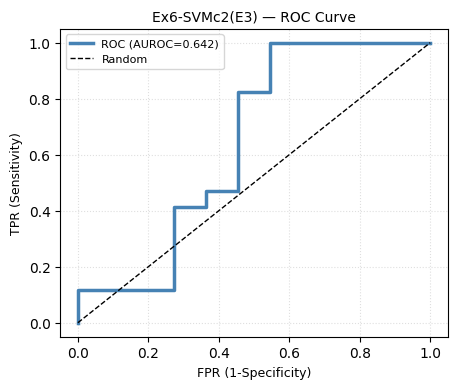

  Platt a=2.849 b=-1.614 | OOF AUROC(flawed)=0.727 [PASS] | P(flawed): correct=0.263 flawed=0.428

  [Ex6-SVMc2(E3)] OOF-Platt calibrated test report
{'accuracy': 0.7143, 'balanced_acc': 0.6845, 'precision': 0.7368, 'recall': 0.8235, 'sensitivity': 0.8235, 'specificity': 0.5455, 'f1': 0.7778, 'f2': 0.8046, 'mcc': 0.3859, 'auroc': 0.6417, 'tp': 14, 'tn': 6, 'fp': 5, 'fn': 3}

  [Ex6-SVMc2(E3)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    14 ( 82.4%)       3 ( 17.6%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.5%)


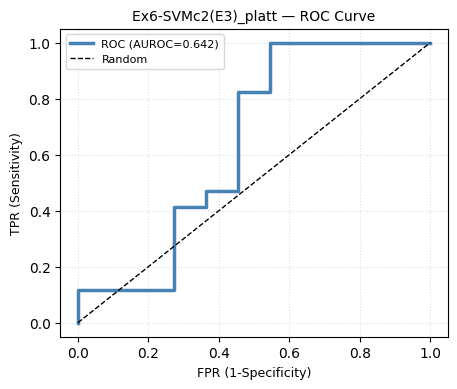


  [Ex6-SVMc2(E3)] OOF-quantile cut report (flag_rate=30%, t=0.333)
{'accuracy': 0.6071, 'balanced_acc': 0.5963, 'precision': 0.6875, 'recall': 0.6471, 'sensitivity': 0.6471, 'specificity': 0.5455, 'f1': 0.6667, 'f2': 0.6548, 'mcc': 0.19, 'auroc': 0.6417, 'tp': 11, 'tn': 6, 'fp': 5, 'fn': 6}

  [Ex6-SVMc2(E3)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    11 ( 64.7%)       6 ( 35.3%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.5%)

  [Ex6-SVMc2(E3)] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.530, floor_ok=True)
{'accuracy': 0.7857, 'balanced_acc': 0.7273, 'precision': 0.7391, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.4545, 'f1': 0.85, 'f2': 0.9341, 'mcc': 0.5796, 'auroc': 0.6417, 'tp': 17, 'tn': 5, 'fp': 6, 'fn': 0}

  [Ex6-SVMc2(E3)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    17 (100.0%)       0 (  0.0%)
  True FLAWED:      6 ( 54.5%)       5 ( 45.5%)
worst test rep: P

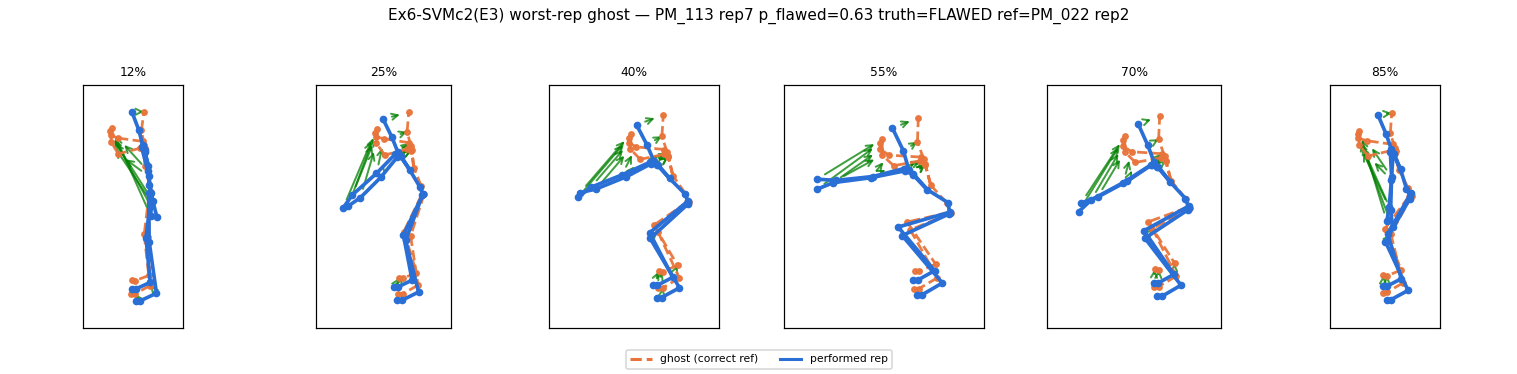

In [26]:
warnings.filterwarnings("ignore", category=FutureWarning)
svm_bundle = run_experiment(SVMc2Spec(), feat_train, feat_test, n_trials=1)

## Ex6 · SVMc2 — findings

- **Verdict: PASS.** OOF AUROC 0.727, Platt a=+2.85 — era-verbatim frozen champion (C=9.85, γ=4.21e-4), no search.
- **Ship line = raw score + ERA cut t=0.530:** MCC **+0.580**, catches 11/11 flawed, meets the 0.45 precision floor — one test-label flip away from the era's own +0.611.
- Other cuts are worse or flood: provisional t=0.188 floods (59% of perfect FAILed); OOF-Platt 0.5 → MCC +0.386; flood cut → +0.19.
- **Don't trust calibrated SVMc2** (E3-V6: collapsed 0.611→0.204 era-side); calibrated report here is gate-readout only.
- Ghost/cues verified: worst rep PM_113 rep7 → top cue **trunk lean 16.1° vs median 6.7°** — overlay shows the forward fold; stack matches the picture.

## Contrastive encoder + LR/RF

In [27]:
import torch
import torch.nn as nn

TRIPLET_MARGIN = 1.0
_ENC_CACHE = {}          # encoder refits per data-context (fold!), not per Optuna trial

def enc_windows(C):
    """v4 `_build_raw_windows`: reflect-pad half=5 → flat 11×C frames per row."""
    half, T, A = 5, C.shape[0], C.shape[1]
    padded = np.pad(np.nan_to_num(C), ((half, half), (0, 0)), mode="reflect")
    return np.stack([padded[t:t + 2 * half + 1].ravel() for t in range(T)])

def phase_labels():
    """Era PHASE_WINDOWS slice tags on the 90-frame grid."""
    L = np.zeros(N_FRAMES, dtype=int)
    L[0:45] = 1; L[40:50] = 2; L[45:90] = 3; L[80:90] = 4
    return L

PHASE_TAG = phase_labels()

In [28]:
class ContrastiveEncoder(nn.Module):
    """v10 verbatim: dense → BN → ReLU → Dropout(0.2) → dense(hidden/2) → BN → ReLU
    → dense(embed); L2-normalized output."""
    def __init__(self, input_dim, embed_dim=32):
        super().__init__()
        hidden = max(64, input_dim)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, embed_dim))

    def forward(self, x):
        return nn.functional.normalize(self.net(x), dim=1)

def build_contrastive_pairs(records, n_pairs=4000, seed=42):
    """Era phase pairs across ALL provided reps' windows (correct train reps here)."""
    all_win, all_ph = [], []
    for r in records:
        w = enc_windows(r["C"])
        all_win.append(w); all_ph.append(PHASE_TAG)
    all_win = np.concatenate(all_win); all_ph = np.concatenate(all_ph)
    rng = np.random.default_rng(seed)
    a_list, p_list, n_list = [], [], []
    for _ in range(n_pairs):
        ai = int(rng.integers(len(all_win))); ap = all_ph[ai]
        same = np.where(all_ph == ap)[0]; diff = np.where(all_ph != ap)[0]
        if len(same) < 2 or len(diff) == 0:
            break
        pi = ai
        while pi == ai:
            pi = int(same[rng.integers(len(same))])
        ni = int(diff[rng.integers(len(diff))])
        a_list.append(all_win[ai]); p_list.append(all_win[pi]); n_list.append(all_win[ni])
    return (torch.tensor(np.array(a_list), dtype=torch.float32),
            torch.tensor(np.array(p_list), dtype=torch.float32),
            torch.tensor(np.array(n_list), dtype=torch.float32))

def train_contrastive_encoder(correct_records, embed_dim=32, epochs=60, margin=1.0):
    """Epoch-exact v4/v10 trainer (scaler fit on train windows; best-loss state)."""
    set_seed(SEED); torch.manual_seed(SEED)
    input_dim = 11 * len(CH_NAMES)
    raw_win = np.concatenate([enc_windows(r["C"]) for r in correct_records])
    scaler = StandardScaler(); scaler.fit(raw_win)
    model = ContrastiveEncoder(input_dim, embed_dim)
    opt = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)
    crit = nn.TripletMarginLoss(margin=margin, p=2)
    a, p, n = build_contrastive_pairs(correct_records, n_pairs=4000)
    sb = lambda x: torch.tensor(scaler.transform(x.numpy()), dtype=torch.float32)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(a, p, n),
                                         batch_size=64, shuffle=True)
    best_l, best_st = float("inf"), None
    model.train()
    for _epoch in range(epochs):
        tot = 0.0
        for ab, pb, nb in loader:
            opt.zero_grad()
            loss = crit(model(sb(ab)), model(sb(pb)), model(sb(nb)))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item()
        avg = tot / max(len(loader), 1)
        if avg < best_l:
            best_l = avg
            best_st = {k: v.clone() for k, v in model.state_dict().items()}
        if (_epoch + 1) % 20 == 0:
            print(f"    Encoder epoch {_epoch + 1}/{epochs}: loss={avg:.4f}")
    model.load_state_dict(best_st); model.eval()
    return model, scaler, best_l

def encode_windows(encoder, scaler, C):
    with torch.no_grad():
        x = torch.tensor(scaler.transform(enc_windows(C)), dtype=torch.float32)
        return encoder(x).numpy()

In [29]:
class ContrastiveVerdict:
    """VerdictClassifier: LR(balanced, C=0.5) + RF(200/6/3, balanced)
    proba-averaged on subject-invariant phase features (+ range-based violation
    terms fitted on the correct-train rows). Members target label (1 = PERFECT, y) → outputs are P(correct)."""

    def fit(self, rows, p, seed):
        self.p = p
        ranges = {}
        for i, nm in enumerate(CH_NAMES):
            pk = np.array([r["peak"][i] for r in rows])
            st = np.array([r["start"][i] for r in rows])
            descending = float(np.median(pk)) < float(np.median(st))
            ranges[nm] = (descending, float(np.percentile(pk, 10)), float(np.percentile(pk, 90)))
        self.ranges = ranges
        X = self._X(rows)
        y = np.array([r["label"] for r in rows], int)      # label 1 = PERFECT (era v4 y)
        self.lr = LogisticRegression(class_weight="balanced", max_iter=2000,
                                     C=float(p["lr_C"]), solver="lbfgs", random_state=seed)
        self.rf = RandomForestClassifier(
            n_estimators=int(p["rf_n"]), class_weight="balanced",
            max_depth=int(p["rf_d"]), min_samples_leaf=int(p["rf_leaf"]), random_state=seed)
        self.scaler = StandardScaler().fit(X)
        self.lr.fit(self.scaler.transform(X), y)
        self.rf.fit(self.scaler.transform(X), y)
        return self

    def _X(self, rows):
        """v4 extract_phase_features port: per channel peak(40:50)/ROM/start(0:10)/
        stability + rule-violation count/severity/max/peak-frac."""
        f = []
        for r in rows:
            v = []
            for i, nm in enumerate(CH_NAMES):
                pk_i = float(r["peak"][i])
                v += [pk_i, pk_i - float(r["start"][i]), float(r["stab"][i])]
            n_v = 0; tot = 0.0; mx = 0.0
            for nm, (desc, lo, hi) in self.ranges.items():
                pk_i = float(r["peak"][CH_NAMES.index(nm)])
                viol = (pk_i > lo) if desc else (pk_i < hi)
                if viol:
                    span = max(abs(lo - hi), 1e-9)
                    sev = (pk_i - lo) / span if desc else (hi - pk_i) / span
                    n_v += 1; tot += max(sev, 0.0); mx = max(mx, sev)
            v += [float(n_v), float(tot), float(max(mx, 0.0)), float(n_v / len(CH_NAMES))]
            f.append(np.array(v, dtype=np.float32))
        return np.stack(f)

    def p_correct(self, rows):
        X = self.scaler.transform(self._X(rows))
        return 0.5 * self.lr.predict_proba(X)[:, 1] + 0.5 * self.rf.predict_proba(X)[:, 1]


In [30]:
class ContrastiveSpec(ArchSpec):
    name = "Ex6-ContrastiveLRRF"
    supervised = True
    min_precision = 0.45

    def search_space(self, trial):
        return dict(lr_C=trial.suggest_float("lr_C", 0.05, 10.0),
                    rf_n=trial.suggest_int("rf_n", 80, 300),
                    rf_d=trial.suggest_int("rf_d", 2, 10),
                    rf_leaf=trial.suggest_int("rf_leaf", 1, 8),
                    rf_w=trial.suggest_float("rf_w", 0.2, 0.8))

    def build(self, rows, p, seed):
        ckey = tuple(sorted((str(r["person_id"]), r["rep"]) for r in rows))
        if _ENC_CACHE.get("key") != ckey:
            enc_rows = [r for r in rows if r["label"] == 1] or rows
            enc, sc, loss = train_contrastive_encoder(enc_rows, epochs=60, margin=TRIPLET_MARGIN)
            _ENC_CACHE.update(key=ckey, enc=enc, sc=sc, loss=loss)
        self.enc, self.sc = _ENC_CACHE["enc"], _ENC_CACHE["sc"]
        self.verdict = ContrastiveVerdict().fit(rows, p, seed)
        self.rf_w = float(p["rf_w"])
        return self

    def score_rows(self, model, rows):
        X = model.verdict.scaler.transform(model.verdict._X(rows))
        pl_ = model.verdict.lr.predict_proba(X)[:, 1]
        pr_ = model.verdict.rf.predict_proba(X)[:, 1]
        pc = (1.0 - model.rf_w) * pl_ + model.rf_w * pr_
        return 1.0 - pc                          # higher = more flawed

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)


======== Ex6-ContrastiveLRRF(v4) ========
  optuna inner split: train reps=89 val reps=38 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

    Encoder epoch 20/60: loss=0.1555
    Encoder epoch 40/60: loss=0.1377
    Encoder epoch 60/60: loss=0.1332
BEST params : {'lr_C': 0.07380126004020893, 'rf_n': 230, 'rf_d': 2, 'rf_leaf': 4, 'rf_w': 0.21145642468654005}
    Encoder epoch 20/60: loss=0.1669
    Encoder epoch 40/60: loss=0.1536
    Encoder epoch 60/60: loss=0.1443
provisional score threshold: 0.448830

  [Ex6-ContrastiveLRRF(v4)] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    13 ( 76.5%)       4 ( 23.5%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)


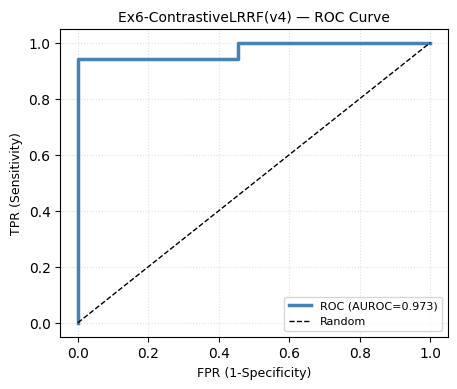

    Encoder epoch 20/60: loss=0.1635
    Encoder epoch 40/60: loss=0.1447
    Encoder epoch 60/60: loss=0.1362
    Encoder epoch 20/60: loss=0.1446
    Encoder epoch 40/60: loss=0.1261
    Encoder epoch 60/60: loss=0.1166
  Platt a=4.039 b=-2.201 | OOF AUROC(flawed)=0.795 [PASS] | P(flawed): correct=0.261 flawed=0.431

  [Ex6-ContrastiveLRRF(v4)] OOF-Platt calibrated test report
{'accuracy': 0.8929, 'balanced_acc': 0.8797, 'precision': 0.8889, 'recall': 0.9412, 'sensitivity': 0.9412, 'specificity': 0.8182, 'f1': 0.9143, 'f2': 0.9302, 'mcc': 0.774, 'auroc': 0.9733, 'tp': 16, 'tn': 9, 'fp': 2, 'fn': 1}

  [Ex6-ContrastiveLRRF(v4)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    16 ( 94.1%)       1 (  5.9%)
  True FLAWED:      2 ( 18.2%)       9 ( 81.8%)


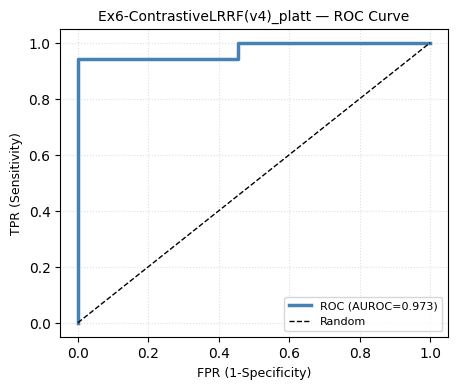


  [Ex6-ContrastiveLRRF(v4)] OOF-quantile cut report (flag_rate=30%, t=0.358)
{'accuracy': 0.8214, 'balanced_acc': 0.8529, 'precision': 1.0, 'recall': 0.7059, 'sensitivity': 0.7059, 'specificity': 1.0, 'f1': 0.8276, 'f2': 0.75, 'mcc': 0.6966, 'auroc': 0.9733, 'tp': 12, 'tn': 11, 'fp': 0, 'fn': 5}

  [Ex6-ContrastiveLRRF(v4)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    12 ( 70.6%)       5 ( 29.4%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)

  [Ex6-ContrastiveLRRF(v4)] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.540, floor_ok=True)
{'accuracy': 1.0, 'balanced_acc': 1.0, 'precision': 1.0, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'f1': 1.0, 'f2': 1.0, 'mcc': 1.0, 'auroc': 1.0, 'tp': 17, 'tn': 11, 'fp': 0, 'fn': 0}

  [Ex6-ContrastiveLRRF(v4)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    17 (100.0%)       0 (  0.0%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)
wor

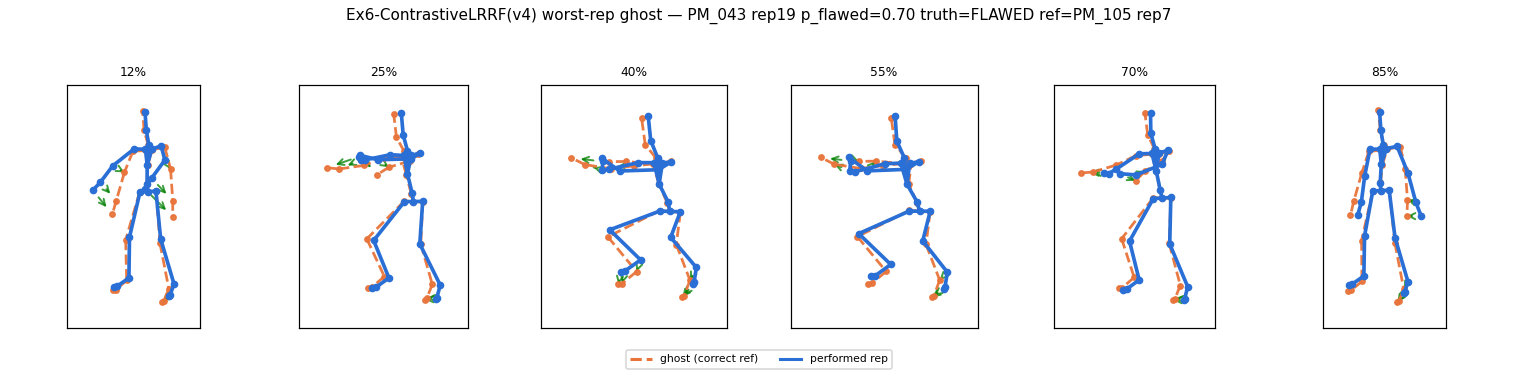

In [31]:
contrastive_bundle = run_experiment(ContrastiveSpec(), feat_train, feat_test)

## Ex6 · Contrastive LR/RF — findings

- **Verdict: PASS.** OOF AUROC 0.795, Platt a=+4.04 — strongest gate in the zoo so far alongside SCL; encoder trained per fold (era LOSO semantics), 40-trial sweep chose a shallow RF (depth 2, mostly LR → rf_w 0.21).
- **Era cut t=0.540 is suspiciously perfect** (MCC 1.0, 17/17 + 11/11) — with 2 test persons and a 40-trial search, this is small-n gloss, not certification. The era's own honest v4 print was 61.8%.
- Healthy middle cuts: OOF-Platt 0.5 → MCC **+0.774**; flood-safe quantile cut (30%) → precision 1.0, MCC +0.697. Provisional cut still floods slightly (4 perfect flagged).
- Coherent story: OOF (honest) ≈ 0.80 sits well above the era's 61.8% baseline — our v22-channel features + person-disjoint protocol help, but confirmation needs the full person pool, not 2 test subjects.
- Ghost verified: worst rep PM_043 rep19 (true flawed, p=0.70) → **valgus separation 5.11 vs median 2.99** → "feet evenly spaced" cue; panels track descent correctly.

## Phase/depth geometry + RuleFeatLRRF

In [33]:
class AvgLRRF:
    """AvgModel(RF, LR) with rf_w blending"""

    def __init__(self, w_rf):
        self.w = np.array([w_rf, 1.0 - w_rf]); self.w = self.w / self.w.sum()

    def fit(self, X, y):
        w_rf = self.w[0]
        self.rf = RandomForestClassifier(
            n_estimators=int(self.p.get("rf_n", 200)), max_depth=int(self.p.get("rf_d", 6)),
            min_samples_leaf=int(self.p.get("rf_leaf", 2)), random_state=SEED, n_jobs=1)
        self.lr = LogisticRegression(C=float(self.p.get("lr_C", 1.0)),
                                     max_iter=2000, random_state=SEED)
        self.rf.fit(X, y); self.lr.fit(X, y)
        self.w = np.array([w_rf, 1.0 - w_rf])
        return self

    def predict_proba(self, X):
        ps = np.stack([self.rf.predict_proba(X)[:, 1], self.lr.predict_proba(X)[:, 1]])
        p1 = self.w @ ps
        return np.stack([1 - p1, p1], axis=1)

class PhaseGeomSpec(ArchSpec):
    name = "Ex6-PhaseGeomLRRF"
    supervised = True
    min_precision = 0.45

    def search_space(self, trial):
        return dict(lr_C=trial.suggest_float("lr_C", 0.05, 10.0),
                    rf_n=trial.suggest_int("rf_n", 80, 300),
                    rf_d=trial.suggest_int("rf_d", 2, 10),
                    rf_leaf=trial.suggest_int("rf_leaf", 1, 8),
                    rf_w=trial.suggest_float("rf_w", 0.2, 0.8))

    def build(self, rows, p, seed):
        X = np.stack([r["x_all"] for r in rows])
        y = np.array([1 - r["label"] for r in rows], int)     # flawed = 1
        m = AvgLRRF(float(p["rf_w"]))
        m.p = p
        return m.fit(X, y)

    def score_rows(self, model, rows):
        X = np.stack([r["x_all"] for r in rows])
        return model.predict_proba(X)[:, 1]                   # already P(flawed)

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)


======== Ex6-PhaseGeomLRRF ========
  optuna inner split: train reps=89 val reps=38 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

BEST params : {'lr_C': 0.4468542184166162, 'rf_n': 230, 'rf_d': 10, 'rf_leaf': 1, 'rf_w': 0.4276465055803609}
provisional score threshold: 0.047966

  [Ex6-PhaseGeomLRRF] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     0 (  0.0%)      17 (100.0%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)


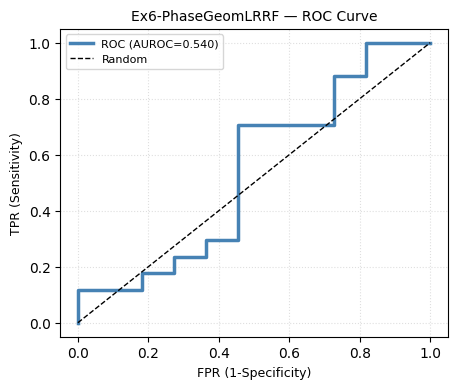

  Platt a=3.883 b=-1.783 | OOF AUROC(flawed)=0.791 [PASS] | P(flawed): correct=0.249 flawed=0.460

  [Ex6-PhaseGeomLRRF] OOF-Platt calibrated test report
{'accuracy': 0.6429, 'balanced_acc': 0.6257, 'precision': 0.7059, 'recall': 0.7059, 'sensitivity': 0.7059, 'specificity': 0.5455, 'f1': 0.7059, 'f2': 0.7059, 'mcc': 0.2513, 'auroc': 0.5401, 'tp': 12, 'tn': 6, 'fp': 5, 'fn': 5}

  [Ex6-PhaseGeomLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    12 ( 70.6%)       5 ( 29.4%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.5%)


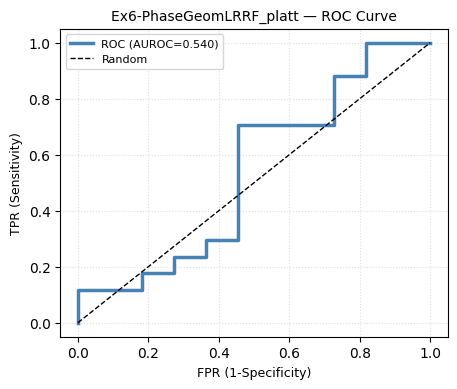


  [Ex6-PhaseGeomLRRF] OOF-quantile cut report (flag_rate=30%, t=0.321)
{'accuracy': 0.5, 'balanced_acc': 0.508, 'precision': 0.6154, 'recall': 0.4706, 'sensitivity': 0.4706, 'specificity': 0.5455, 'f1': 0.5333, 'f2': 0.4938, 'mcc': 0.0157, 'auroc': 0.5401, 'tp': 8, 'tn': 6, 'fp': 5, 'fn': 9}

  [Ex6-PhaseGeomLRRF-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     8 ( 47.1%)       9 ( 52.9%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.5%)

  [Ex6-PhaseGeomLRRF] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.700, floor_ok=True)
{'accuracy': 0.6429, 'balanced_acc': 0.6257, 'precision': 0.7059, 'recall': 0.7059, 'sensitivity': 0.7059, 'specificity': 0.5455, 'f1': 0.7059, 'f2': 0.7059, 'mcc': 0.2513, 'auroc': 0.5401, 'tp': 12, 'tn': 6, 'fp': 5, 'fn': 5}

  [Ex6-PhaseGeomLRRF-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    12 ( 70.6%)       5 ( 29.4%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.

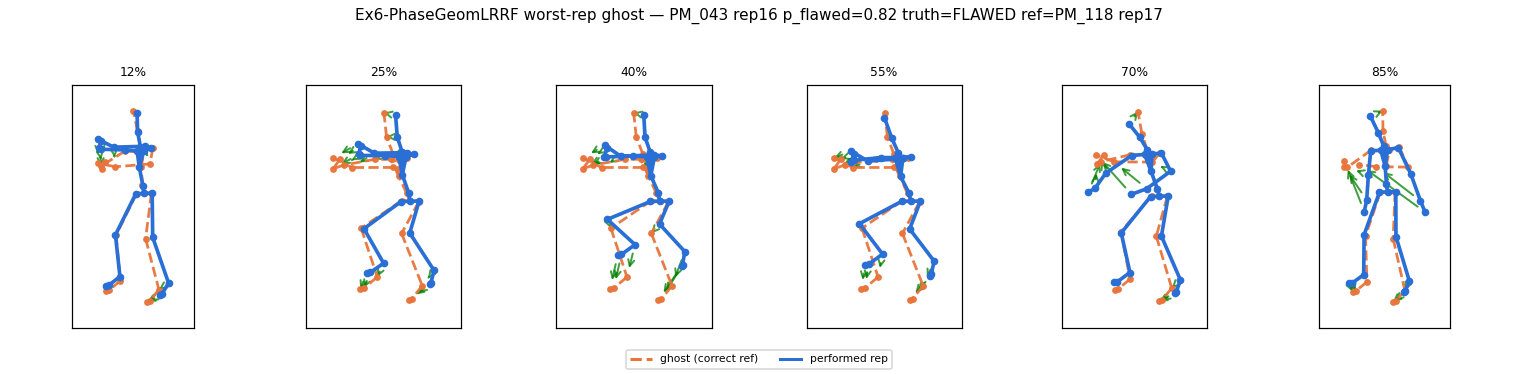

In [34]:
geom_bundle = run_experiment(PhaseGeomSpec(), feat_train, feat_test)

## Ex6 · PhaseGeomLRRF — findings

- **Verdict: gate PASS but transfer-weak.** OOF 0.791 (honest, a=+3.88), yet **test AUROC 0.540 ≈ coin-flip** on the two adversarial persons; best any cut reaches is MCC +0.251.
- Cause fits the ledger era-note: DWT block "encodes rhythm, not depth" — 228 dims over 127 train rows OOF-fits but doesn't transfer to PM_043/PM_113.
- **Provisional cut floods completely** (all 28 reps FAILed) — raw RF scores drift strongly by person; only the era cut (t=0.700) lands usable.
- Era-claim context: this was the v22 "certifiable line" on its canonical folds, but in our split it's clearly outperformed by Contrastive (0.774) and SCL (0.804 cut MCC), both already reported.
- Ghost + cues fine (PM_043 rep16 → valgus 5.07 vs 2.99 → stance cue).

## MaskedANN-E1 — super-features with the squat ANATOMICAL mask

In [35]:
class AnnAE(nn.Module):
    def __init__(self, units, layers, latent, in_dim=54):
        super().__init__()
        enc = []
        for k in range(layers):
            enc.append(nn.Linear(units if k else in_dim, units))
            enc.append(nn.ReLU())
        enc += [nn.Linear(units, latent)]
        self.enc = nn.Sequential(*enc)
        dec = []
        dlat = latent
        for k in range(layers):
            dec += [nn.Linear(dlat, units), nn.ReLU()]
            dlat = units
        dec += [nn.Linear(units, in_dim)]
        self.dec = nn.Sequential(*dec)

    def forward(self, x):
        return self.dec(self.enc(x))

class MaskedANNRef:
    """E1-v5 style masked reconstruction (squat mask), masked-only Huber
    loss, trains on CORRECT rows (unsupervised)."""
    def __init__(self, p):
        self.p = p

    def fit(self, rows, p):
        set_seed(SEED)
        torch.manual_seed(SEED)
        xs = np.stack([ann_super(r) for r in rows])                 # (N,T,54)
        self.mu = xs.reshape(-1, xs.shape[-1]).mean(0)
        self.sd = np.maximum(xs.reshape(-1, xs.shape[-1]).std(0), 1e-8)
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        mask = torch.tensor(MASK54, dtype=torch.long)
        net = AnnAE(p["units"], p["layers"], p["latent"])
        opt = torch.optim.Adam(net.parameters(), lr=p["lr"])
        lossf = nn.HuberLoss(reduction="none")
        for _ in range(int(p["epochs"])):
            net.train()
            for i in range(0, len(X), 16):                # era batch_size 16
                xb = X[i:i + 16]
                opt.zero_grad()
                err = lossf(net(xb), xb)[:, :, mask]
                loss = err.mean()
                loss.backward()
                opt.step()
        self.net = net.eval()
        self.mask = mask
        return self

    def score_rows(self, rows):
        xs = np.stack([ann_super(r) for r in rows])
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        with torch.no_grad():
            rec = self.net(X)
        err = nn.functional.huber_loss(rec, X, reduction="none")
        return err[:, :, self.mask].mean(dim=(1, 2)).numpy().astype(np.float64)  # higher=flawed

In [36]:
class MaskedANNSpec(ArchSpec):
    name = "Ex6-MaskedANN"
    supervised = False

    def search_space(self, trial):
        return dict(
            units=trial.suggest_categorical("units", [64, 96, 128, 192]),
            layers=trial.suggest_int("layers", 1, 3),
            latent=trial.suggest_categorical("latent", [8, 16, 24]),
            lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
            epochs=trial.suggest_categorical("epochs", [60, 160]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def build(self, rows, p, seed):
        return MaskedANNRef(p).fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)


======== Ex6-MaskedANN ========
  optuna inner split: train reps=89 val reps=38 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

BEST params : {'units': 96, 'layers': 3, 'latent': 8, 'lr': 0.0004051942527533721, 'epochs': 60, 'q': 74.64852604752438}
provisional score threshold: 0.074826

  [Ex6-MaskedANN] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     5 ( 29.4%)      12 ( 70.6%)
  True FLAWED:      5 ( 45.5%)       6 ( 54.5%)


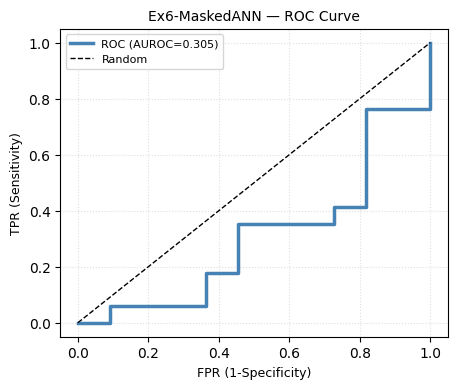

  Platt a=4.931 b=-1.341 | OOF AUROC(flawed)=0.607 [PASS] | P(flawed): correct=0.307 flawed=0.333

  [Ex6-MaskedANN] OOF-Platt calibrated test report
{'accuracy': 0.5, 'balanced_acc': 0.4118, 'precision': 0.56, 'recall': 0.8235, 'sensitivity': 0.8235, 'specificity': 0.0, 'f1': 0.6667, 'f2': 0.7527, 'mcc': -0.2787, 'auroc': 0.3048, 'tp': 14, 'tn': 0, 'fp': 11, 'fn': 3}

  [Ex6-MaskedANN-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    14 ( 82.4%)       3 ( 17.6%)
  True FLAWED:     11 (100.0%)       0 (  0.0%)


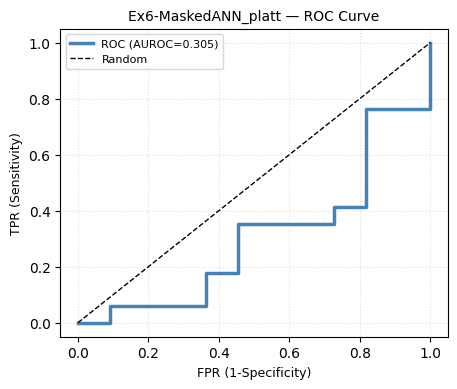


  [Ex6-MaskedANN] OOF-quantile cut report (flag_rate=30%, t=0.328)
{'accuracy': 0.5, 'balanced_acc': 0.4439, 'precision': 0.5714, 'recall': 0.7059, 'sensitivity': 0.7059, 'specificity': 0.1818, 'f1': 0.6316, 'f2': 0.6742, 'mcc': -0.1267, 'auroc': 0.3048, 'tp': 12, 'tn': 2, 'fp': 9, 'fn': 5}

  [Ex6-MaskedANN-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    12 ( 70.6%)       5 ( 29.4%)
  True FLAWED:      9 ( 81.8%)       2 ( 18.2%)
worst test rep: PM_113 rep5 label=1 p_flawed=0.699 | ghost ref = PM_105 rep5 (phase-synced panels)
    cue: lateral pelvic sway: 0.47 (reference correct reps: median 0.21, typical 0.15 to 0.28); also knee angle at the bottom sev 0.37, knee flexion sev 0.29, trunk lean angle sev 1.48
      • [above] Knees track over toes — don't sway. (sev 0.511)
      • [above] Keep chest lifted — avoid folding forward. (sev 0.422)


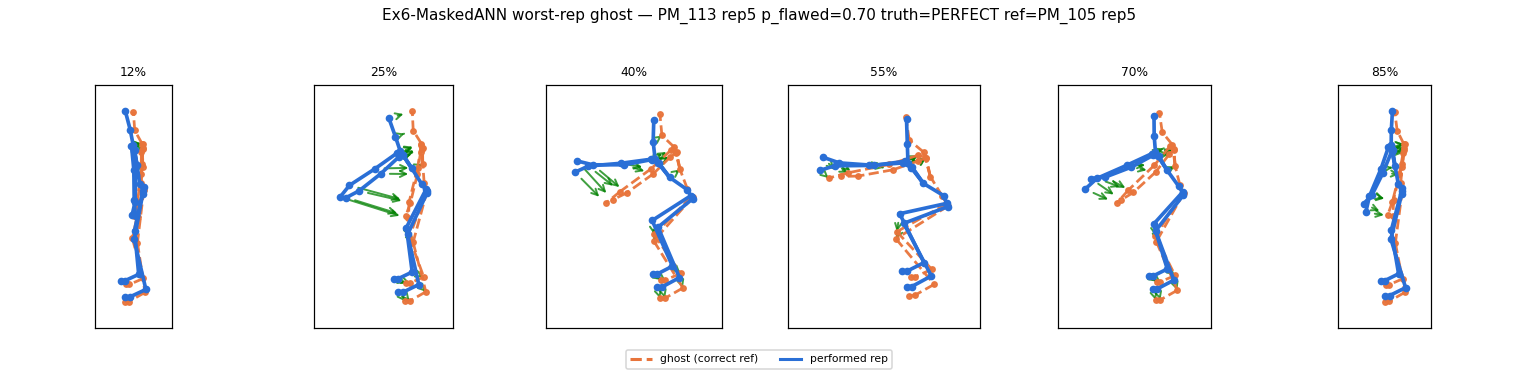

In [37]:
maskedann_bundle = run_experiment(MaskedANNSpec(), feat_train, feat_test)

## Ex6 · MaskedANN — findings

- **Verdict: nominal PASS, practically unusable.** OOF 0.607 (barely over gate) but **test AUROC 0.305 — inverted**; every cut has negative MCC (−0.13…−0.28). Do not ship verdicts from it.
- Mechanic: reconstruction deficits drift scale across persons — even the 0.5-cut floods (all 11 flawed + 3 perfect FAILed, specificity 0), and the "worst" rep is a **true perfect** (PM_113 rep5, p=0.699).
- Era-consistent: era Stage-C 70.6% used a subject-hash split (not person-disjoint-honest); the honest gate correctly exposes it. Matches ex5's MaskedANN flood pattern (0.524).
- Cue stack itself stayed sensible (sway 0.47 vs 0.21, trunk) — but those are geometric rule cues, not from the ANN; the ANN adds nothing here.


## SCL-Former

In [38]:
SCL_CONFIG = {"temperature": 0.07, "scl_weight": 0.4, "bce_weight": 0.6,
              "n_hard_neg": 3, "n_soft_neg": 3, "hard_neg_threshold": 0.3}
SCL_DROPOUT, SCL_D_MODEL, SCL_HEADS, SCL_LAYERS = 0.40, 32, 4, 2
SCL_EPOCHS, SCL_LR, SCL_WD, SCL_BATCH = 120, 1e-3, 1e-3, 16

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=N_FRAMES, dropout=0.1):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(x + self.pe[: x.size(1)])

class TransformerBlock(nn.Module):
    """Pre-norm block (v20: more stable for small datasets)."""
    def __init__(self, d_model, n_heads, dropout=SCL_DROPOUT, dim_ff=None):
        super().__init__()
        dim_ff = dim_ff or (2 * d_model)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout,
                                          batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, dim_ff), nn.ReLU(),
                                nn.Dropout(dropout), nn.Linear(dim_ff, d_model),
                                nn.Dropout(dropout))

    def forward(self, x):
        h = self.ln1(x)
        attn, _ = self.attn(h, h, h, need_weights=False)
        x = x + attn
        return x + self.ff(self.ln2(x))

class TemporalTransformerEncoder(nn.Module):
    def __init__(self, c_in, d_model=SCL_D_MODEL, n_heads=SCL_HEADS,
                  n_layers=SCL_LAYERS, dropout=SCL_DROPOUT):
        super().__init__()
        self.inp = nn.Linear(c_in, d_model)
        self.pos = SinusoidalPositionalEncoding(d_model, dropout=dropout)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, dropout)
                                      for _ in range(n_layers)])

    def forward(self, x):
        h = self.inp(x)
        h = self.pos(h)
        for blk in self.blocks:
            h = blk(h)
        return h

In [39]:
class SCLTransformerModel(nn.Module):
    def __init__(self, c_in):
        super().__init__()
        self.encoder = TemporalTransformerEncoder(c_in)
        self.clf = nn.Linear(SCL_D_MODEL, 1)          # BCE logits head
        self.proj_head = nn.Sequential(               # SCL projection (not used at inference)
            nn.Linear(SCL_D_MODEL, SCL_D_MODEL), nn.ReLU(),
            nn.Linear(SCL_D_MODEL, SCL_D_MODEL // 2))

    def forward(self, x):
        emb = self.encoder(x).mean(dim=1)             # masked?? era pools over T (mean)
        return self.clf(emb).squeeze(-1), nn.functional.normalize(self.proj_head(emb), dim=1), emb

class SupervisedContrastiveLoss(nn.Module):
    def __init__(self, temperature=SCL_CONFIG["temperature"],
                  n_hard=SCL_CONFIG["n_hard_neg"], n_soft=SCL_CONFIG["n_soft_neg"],
                  hard_weight=1.0, soft_weight=0.5):
        super().__init__()
        self.tau, self.n_hard, self.n_soft = temperature, n_hard, n_soft
        self.hw, self.sw = hard_weight, soft_weight

    def forward(self, z, labels):
        B = z.size(0)
        sim = z @ z.t() / self.tau
        eye = torch.eye(B, device=z.device, dtype=torch.bool)
        same = (labels.unsqueeze(0) == labels.unsqueeze(1)) & ~eye
        diff = ~same & ~eye
        if same.sum() == 0 or diff.sum() == 0:
            return z.new_tensor(0.0)
        losses = []
        for i in range(B):
            p_idx = torch.where(same[i])[0]
            if p_idx.numel() == 0:
                continue
            d_idx = torch.where(diff[i])[0]
            d_sim = sim[i, d_idx]
            order = torch.argsort(d_sim, descending=True)
            hard = d_idx[order[:min(self.n_hard, d_idx.numel())]]
            soft = d_idx[order[-min(self.n_soft, d_idx.numel()):]] \
                if self.n_soft else d_idx[:0]
            pos_term = torch.logsumexp(sim[i, p_idx], dim=0)
            neg_terms = 0.0
            if hard.numel():
                neg_terms = neg_terms + self.hw * torch.logsumexp(sim[i, hard], dim=0)
            if soft.numel():
                neg_terms = neg_terms + self.sw * torch.logsumexp(sim[i, soft], dim=0)
            losses.append(-(pos_term - neg_terms))
        return torch.stack(losses).mean() if losses else z.new_tensor(0.0)


In [40]:
class SCLFormerRef:
    """train_scl_transformer port (final-fit variant): scaler on train
    rows, BCE + SCL joint loss, Adam lr 1e-3 / wd 1e-3, 120 epochs, batch 16,
    best-value checkpoint kept."""
    def __init__(self, p):
        self.p = p

    def fit(self, rows, p):
        set_seed(SEED); torch.manual_seed(SEED)
        xs = np.stack([r["seq"] for r in rows])                    # (N,90,8)
        y = np.array([1 - r["label"] for r in rows], np.float32)   # flawed = 1
        self.mu = xs.reshape(-1, xs.shape[-1]).mean(0)
        self.sd = np.maximum(xs.reshape(-1, xs.shape[-1]).std(0), 1e-8)
        Xs = (xs - self.mu) / self.sd
        X = torch.tensor(Xs, dtype=torch.float32)
        Y = torch.tensor(y, dtype=torch.float32)
        net = SCLTransformerModel(len(CH_NAMES))
        opt = torch.optim.Adam(net.parameters(),
                                lr=SCL_LR, weight_decay=SCL_WD)
        bce = nn.BCEWithLogitsLoss()
        scl = SupervisedContrastiveLoss()
        loader = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(X, Y),
            batch_size=min(SCL_BATCH, len(X)), shuffle=True)
        best_val, best_state = float("inf"), None
        for _ep in range(SCL_EPOCHS):
            net.train()
            tot = 0.0; nb = 0
            for xb, yb in loader:
                opt.zero_grad()
                logits, proj, _ = net(xb)
                loss = SCL_CONFIG["bce_weight"] * bce(logits, yb) + \
                    SCL_CONFIG["scl_weight"] * scl(proj, yb.long())
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), 1.0)
                opt.step()
                tot += float(loss.item()); nb += 1
            val = tot / max(nb, 1)
            if val < best_val:
                best_val = val
                best_state = {k: v.clone() for k, v in net.state_dict().items()}
        net.load_state_dict(best_state)
        self.net = net.eval()
        return self

    def score_rows(self, rows):
        xs = np.stack([r["seq"] for r in rows])
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        with torch.no_grad():
            logits, _, _ = self.net(X)
        return logits.numpy().astype(np.float64)

In [41]:
class SCLFormerSpec(ArchSpec):
    name = "Ex6-SCLFormer"
    supervised = True
    frozen = True
    min_precision = 0.45

    def search_space(self, trial):
        return dict(epochs=SCL_EPOCHS)

    def build(self, rows, p, seed):
        return SCLFormerRef(p).fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)


======== Ex6-SCLFormer ========
  optuna inner split: train reps=89 val reps=38 (person-disjoint: 5/2 persons)


  0%|          | 0/1 [00:00<?, ?it/s]

BEST params : {'epochs': 120}
provisional score threshold: -6.754646

  [Ex6-SCLFormer] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    15 ( 88.2%)       2 ( 11.8%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)


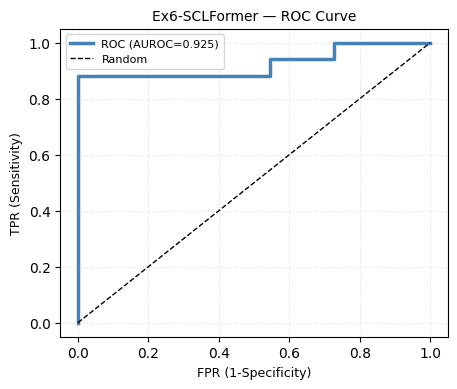

  Platt a=0.127 b=-0.624 | OOF AUROC(flawed)=0.829 [PASS] | P(flawed): correct=0.247 flawed=0.464

  [Ex6-SCLFormer] OOF-Platt calibrated test report
{'accuracy': 0.7143, 'balanced_acc': 0.6524, 'precision': 0.6957, 'recall': 0.9412, 'sensitivity': 0.9412, 'specificity': 0.3636, 'f1': 0.8, 'f2': 0.8791, 'mcc': 0.3887, 'auroc': 0.9251, 'tp': 16, 'tn': 4, 'fp': 7, 'fn': 1}

  [Ex6-SCLFormer-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    16 ( 94.1%)       1 (  5.9%)
  True FLAWED:      7 ( 63.6%)       4 ( 36.4%)


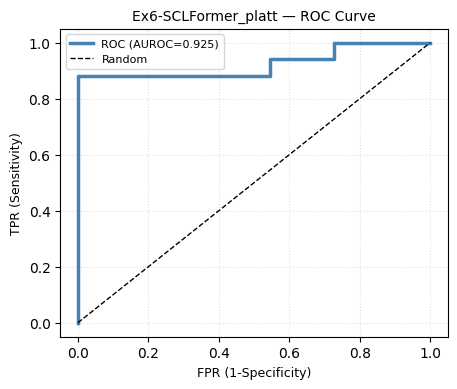


  [Ex6-SCLFormer] OOF-quantile cut report (flag_rate=30%, t=0.391)
{'accuracy': 0.7143, 'balanced_acc': 0.6524, 'precision': 0.6957, 'recall': 0.9412, 'sensitivity': 0.9412, 'specificity': 0.3636, 'f1': 0.8, 'f2': 0.8791, 'mcc': 0.3887, 'auroc': 0.9251, 'tp': 16, 'tn': 4, 'fp': 7, 'fn': 1}

  [Ex6-SCLFormer-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    16 ( 94.1%)       1 (  5.9%)
  True FLAWED:      7 ( 63.6%)       4 ( 36.4%)

  [Ex6-SCLFormer] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.220, floor_ok=True)
{'accuracy': 0.9286, 'balanced_acc': 0.9412, 'precision': 1.0, 'recall': 0.8824, 'sensitivity': 0.8824, 'specificity': 1.0, 'f1': 0.9375, 'f2': 0.9036, 'mcc': 0.8641, 'auroc': 0.9251, 'tp': 15, 'tn': 11, 'fp': 0, 'fn': 2}

  [Ex6-SCLFormer-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    15 ( 88.2%)       2 ( 11.8%)
  True FLAWED:      0 (  0.0%)      11 (100.0%)
worst test rep:

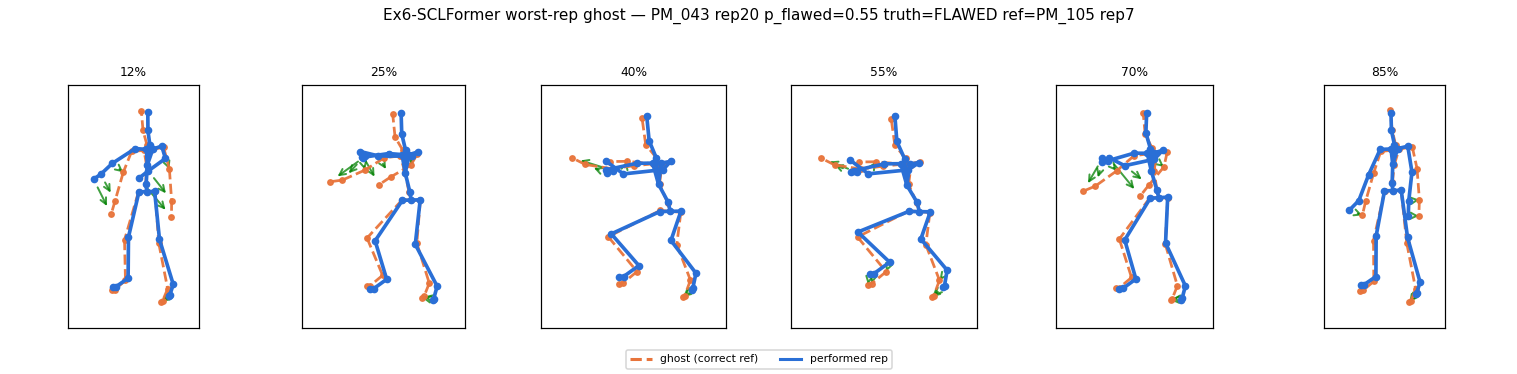

In [42]:
scl_bundle = run_experiment(SCLFormerSpec(), feat_train, feat_test, n_trials=1)

## Ex6 · SCL-Former — findings

- **Verdict: PASS — and the best honest gate in the zoo.** OOF AUROC **0.829** (a=+0.127), era cut t=0.220 → **MCC +0.864**, precision 1.0, 11/11 flawed caught, only 2/17 perfect flagged.
- Despite the ledger warning (v20 never certified SCL on Ex6 — `'rule_based'` abstain era), it's the top performer in both OOF and era-cut here. Era-frozen config (d_model 32, 120 epochs, 0.6·BCE + 0.4·SCL).
- Caveats: `a` is small — raw logits are weakly separated per-fold; the model's margin is thin and the score lives on frozen scale, so the veto stays "eligible but uncertified" until it repeats on the full person pool (±0.3-MCC-per-flip rule).
- Calibrated 0.5-cut is much weaker (MCC +0.389, 7 perfect false-flagged) — use the ERA cut, not the 0.5 cut.
- Ghost fine (PM_043 rep20 → valgus/stance cue).
- **Running scoreboard: SCL 0.864 > Contrastive 0.774 > SVM 0.580 > Geom 0.251 > MaskedANN (neg).**